In [1]:
# Cai dat phien ban supervision phu hop co ho tro ByteTrack
!pip install ultralytics "supervision==0.24.0"
import cv2
import torch
import ultralytics
import supervision as sv

print('OpenCV:', cv2.__version__)
print('PyTorch version:', torch.__version__)
print('Supervision version:', sv.__version__)
print('ByteTrack ho tro:', hasattr(sv, 'ByteTrack'))
print('GPU co san (CUDA):', torch.cuda.is_available())


  Using cached supervision-0.31.3-py3-none-any.whl.metadata (14 kB)
  Using cached av-19.0.2-cp312-abi3-win_amd64.whl.metadata (5.1 kB)
  Using cached pydeprecate-0.13.0-py3-none-any.whl.metadata (107 kB)
   ---------------------------------------- 0.0/1.4 MB ? eta -:--:--
   ------- -------------------------------- 0.3/1.4 MB ? eta -:--:--
   ---------------------------------------- 1.4/1.4 MB 5.9 MB/s  0:00:00
Using cached supervision-0.31.3-py3-none-any.whl (481 kB)
Using cached pydeprecate-0.13.0-py3-none-any.whl (203 kB)
Using cached av-19.0.2-cp312-abi3-win_amd64.whl (28.2 MB)

   ---------------------------------------- 0/6 [pydeprecate]
   ---------------------------------------- 0/6 [pydeprecate]
   ---------------------------------------- 0/6 [pydeprecate]
   ---------------------------------------- 0/6 [pydeprecate]
   ------ --------------------------------- 1/6 [av]
   ------ --------------------------------- 1/6 [av]
   ------ --------------------------------- 1/6 [av]
  


[notice] A new release of pip is available: 26.2.1 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip
d:\Python AI\.venv313\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


OpenCV: 5.0.0
PyTorch version: 2.14.0+cpu
Supervision version: 0.31.3
GPU co san (CUDA): False


In [2]:
import os
import sys

# 1. Tự động định vị thư mục gốc Football_Analyst_Project (chạy tốt trên cả máy nội bộ và Colab)
def get_project_root():
    curr = os.path.abspath(os.getcwd())
    while curr and os.path.dirname(curr) != curr:
        if os.path.exists(os.path.join(curr, 'Tracker', 'Tracker.py')):
            return curr
        if os.path.exists(os.path.join(curr, 'Football_Analyst_Project', 'Tracker', 'Tracker.py')):
            return os.path.join(curr, 'Football_Analyst_Project')
        curr = os.path.dirname(curr)
    if os.path.exists('/content/Football_Analyst_Project'):
        return '/content/Football_Analyst_Project'
    return os.path.abspath(os.path.join(os.getcwd(), '..'))

project_root = get_project_root()
print(f'Project Root: {project_root}')

# Thêm project_root vào đầu sys.path để import Tracker và Utils
if project_root not in sys.path:
    sys.path.insert(0, project_root)

# 2. Import Tracker và các tiện ích
from Tracker import Tracker
from Utils import read_video, save_video
import cv2
from ultralytics import YOLO

# 3. Đường dẫn tuyệt đối chuẩn xác dựa trên project_root
input_video_path = os.path.join(project_root, 'Inputs', 'Match_Video.mp4')
output_video_path = os.path.join(project_root, 'Outputs', 'Match_Video_Processed.mp4')
model_path = os.path.join(project_root, 'Models', 'best.pt')
stub_path = os.path.join(project_root, 'Stubs', 'stub.pkl')

# Đọc video và trích xuất frames
frames = read_video(input_video_path)

# Khởi tạo tracker với model_path rõ ràng
tracker = Tracker(model_path)
tracks = tracker.get_objects_tracked(frames, use_stub=True, stub_path=stub_path)
print(f'Đã đọc {len(frames)} frames và trích xuất tracks thành công!')

Project Root: d:\Python AI\Personal_Project\Football_Analyst_Project
Đang đọc video: 100.0% (750/750 frames)
Đã đọc 750 frames và trích xuất tracks thành công!


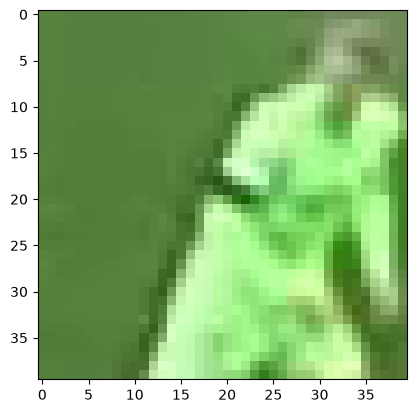

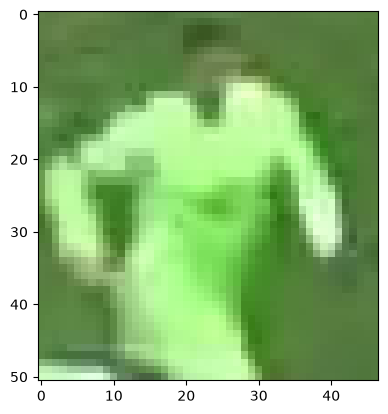

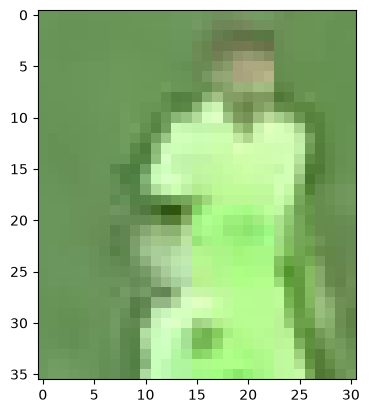

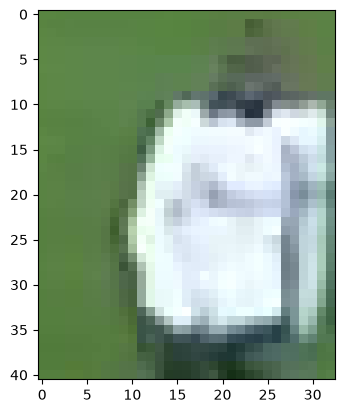

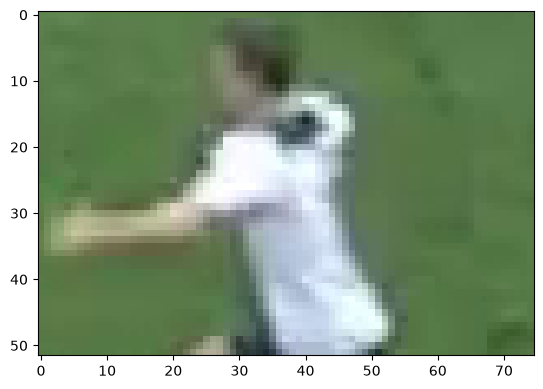

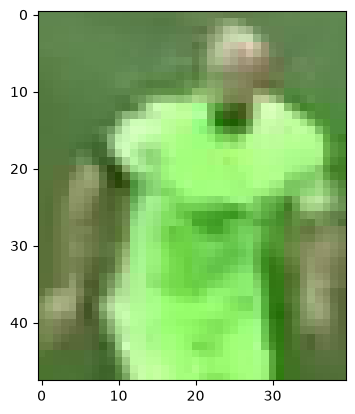

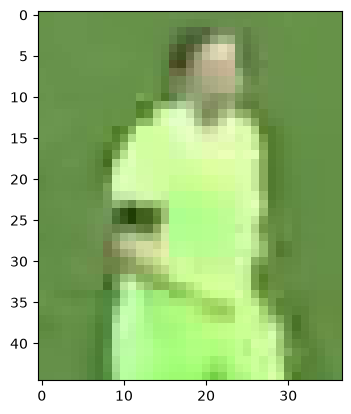

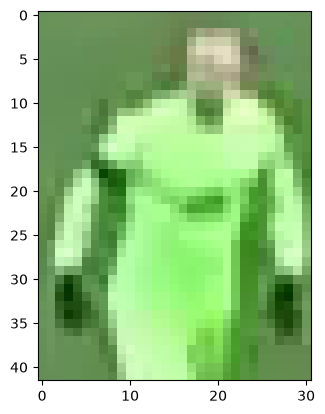

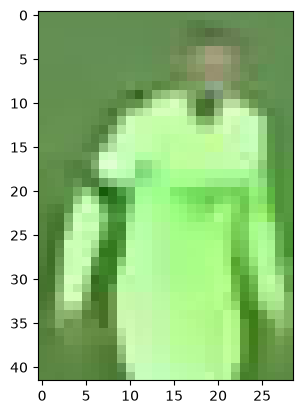

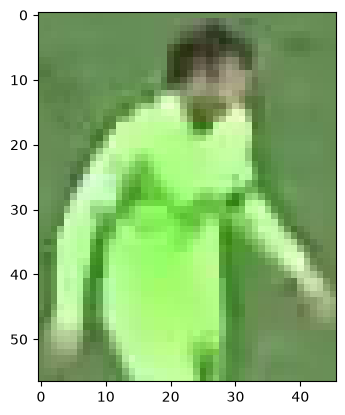

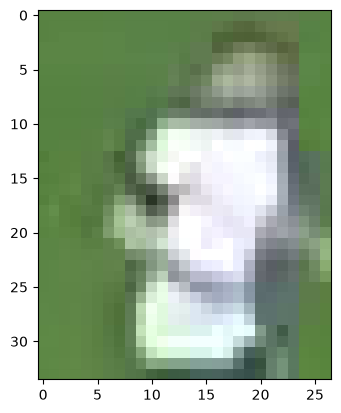

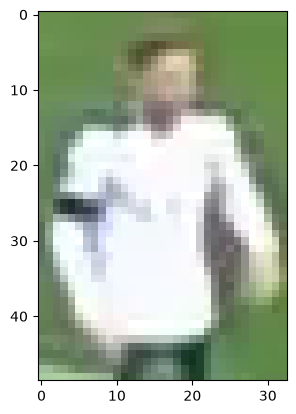

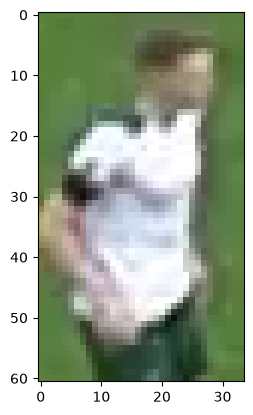

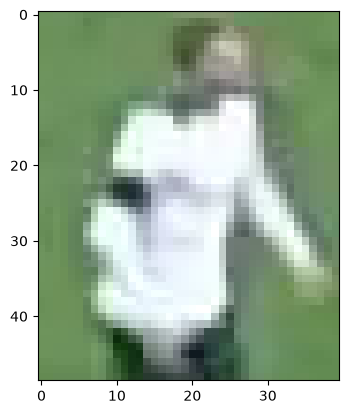

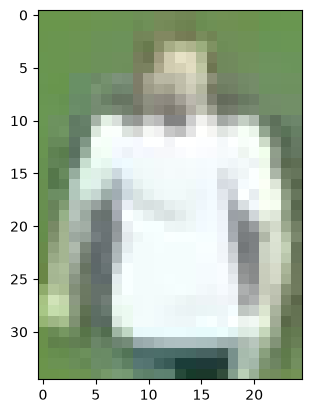

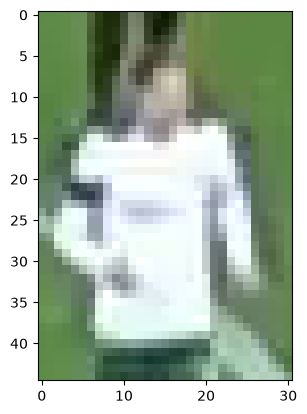

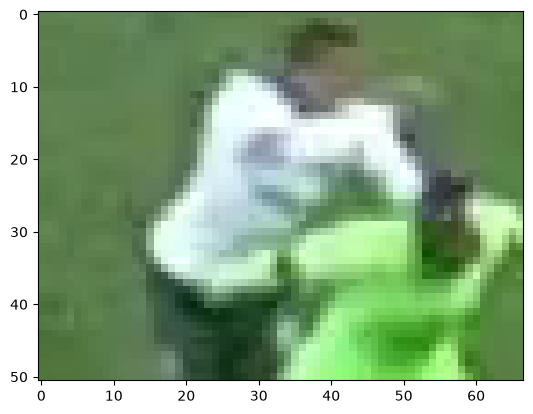

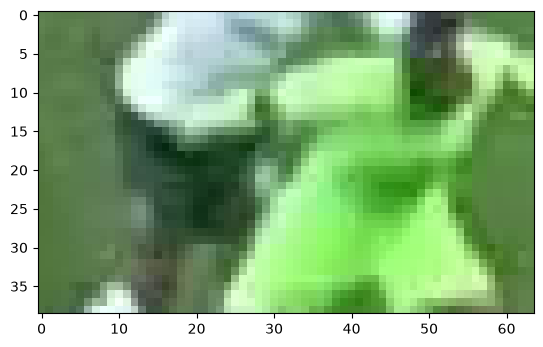

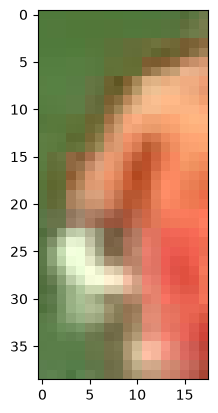

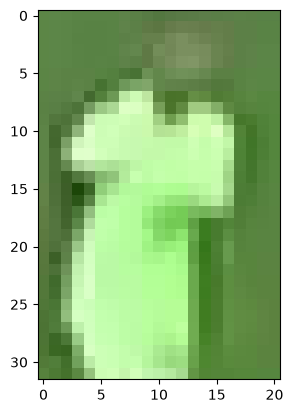

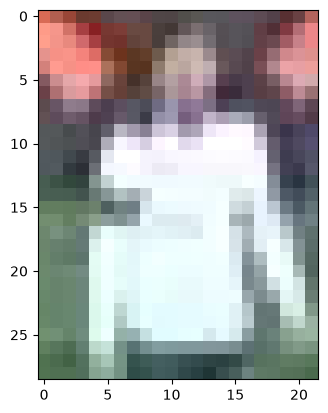

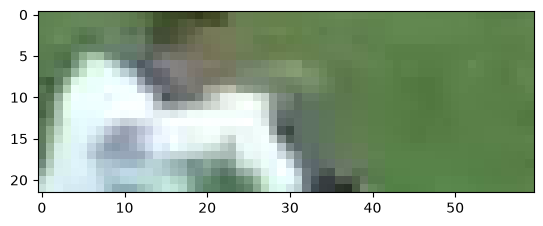

In [3]:
# iterate through the first few frames to sample player colors
import matplotlib.pyplot as plt
sample_frames = min(50, len(frames))
for f_idx in range(sample_frames):
	frame = frames[f_idx]
	player_tracks = tracks["player"][f_idx]

	for track_id, track in player_tracks.items():
					# get the bounding box of the player
					x1, y1, x2, y2 = [int(x) for x in track["bbox"]]
					h = y2 - y1
					upper_body = frame[y1 : y1 + int(h * 0.6), x1:x2]
					#using matplotlib to display the upper body of the player
					plt.imshow(cv2.cvtColor(upper_body, cv2.COLOR_BGR2RGB))
					plt.show()
				
	break